In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.options.display.float_format = '{:.2f}'.format

In [6]:
#call the Dataframes - 'customers', 'products' and 'transactions'
customers = pd.read_csv('../csv/Customers_list.csv', encoding = 'latin-1')
products = pd.read_csv('../csv/Products_list.csv', encoding = 'latin-1')
transactions = pd.read_csv('../csv/Transactions_list.csv', encoding = 'latin-1')
#.head reduces the output
customers.head(1)

transactions.head(1)

,CustomerID,ProductID,PurchaseCount,LastPurchaseDays,Spend
0,1,171,1,82,462.89


In [7]:
products.head(1)

,ProductID,Category,Brand,Price,Rating,PopularityScore
0,1,Fitness,PrimeGoods,66.68,4.35,1


In [8]:
transactions.head(1)

,CustomerID,ProductID,PurchaseCount,LastPurchaseDays,Spend
0,1,171,1,82,462.89


In [9]:
print(customers.shape, products.shape, transactions.shape)
print(customers.dtypes, '\n')
print(products.dtypes, '\n')
print(transactions.dtypes)

(1000, 5) (200, 6) (18829, 5)
CustomerID         int64
AgeGroup             str
Region               str
LoyaltyLevel         str
MembershipYears    int64
dtype: object 

ProductID            int64
Category               str
Brand                  str
Price              float64
Rating             float64
PopularityScore      int64
dtype: object 

CustomerID            int64
ProductID             int64
PurchaseCount         int64
LastPurchaseDays      int64
Spend               float64
dtype: object


In [10]:
print(customers.isnull().sum(), '\n')
print(products.isnull().sum(), '\n')
print(transactions.isnull().sum())

CustomerID         0
AgeGroup           0
Region             0
LoyaltyLevel       0
MembershipYears    0
dtype: int64 

ProductID           0
Category            0
Brand               0
Price               0
Rating             15
PopularityScore     0
dtype: int64 

CustomerID          0
ProductID           0
PurchaseCount       0
LastPurchaseDays    0
Spend               0
dtype: int64


In [11]:
print(customers.duplicated().sum())
print(products.duplicated().sum())
print(transactions.duplicated().sum())
transactions = transactions.drop_duplicates().reset_index(drop=True)

0
0
386


In [12]:
#15 products have no Rating, so fill with the median
products['Rating'] = products['Rating'].fillna(products['Rating'].median())
products.isnull().sum()

ProductID          0
Category           0
Brand              0
Price              0
Rating             0
PopularityScore    0
dtype: int64

In [13]:
print((~transactions['CustomerID'].isin(customers['CustomerID'])).sum())
print((~transactions['ProductID'].isin(products['ProductID'])).sum())

0
0


In [14]:
#Why aggregate: a recommender needs one score per customer-product pair.
transactions_agg = transactions.groupby(['CustomerID', 'ProductID']).agg(
    PurchaseCount = ('PurchaseCount', 'sum'),
    Spend = ('Spend', 'sum'),
    LastPurchaseDays = ('LastPurchaseDays', 'min')).reset_index()
transactions_agg.shape

(10263, 5)

In [15]:
df = transactions_agg.merge(customers, on = 'CustomerID', how = 'left')
df = df.merge(products, on = 'ProductID', how = 'left')
df.head(1)

,CustomerID,ProductID,PurchaseCount,Spend,LastPurchaseDays,AgeGroup,Region,LoyaltyLevel,MembershipYears,Category,Brand,Price,Rating,PopularityScore
0,1,171,1,462.89,82,50+,South,Bronze,8,Electronics,TechMax,449.12,4.36,2


In [16]:
print(df.isnull().sum().sum(), df.duplicated().sum(), df.shape)

0 0 (10263, 14)


In [17]:
sparsity = 1 - len(df) / (df['CustomerID'].nunique() * df['ProductID'].nunique())
print(round(sparsity * 100, 2), '% of customer-product pairs have no purchase')

94.87 % of customer-product pairs have no purchase


In [18]:
print(products['Category'].value_counts(), '\n')
print(products['Brand'].value_counts())

Category
Fitness        33
Books          33
Kitchen        32
Home           29
Electronics    27
Gaming         26
fitness         5
electronics     5
home            4
kitchen         3
books           2
gaming          1
Name: count, dtype: int64 

Brand
TechMax       45
FitLife       34
PrimeGoods    33
HomePro       32
SmartBuy      29
NextGen       27
Name: count, dtype: int64


In [19]:
products['Category'] = products['Category'].str.strip().str.title()
products['Category'].value_counts()

Category
Fitness        38
Kitchen        35
Books          35
Home           33
Electronics    32
Gaming         27
Name: count, dtype: int64

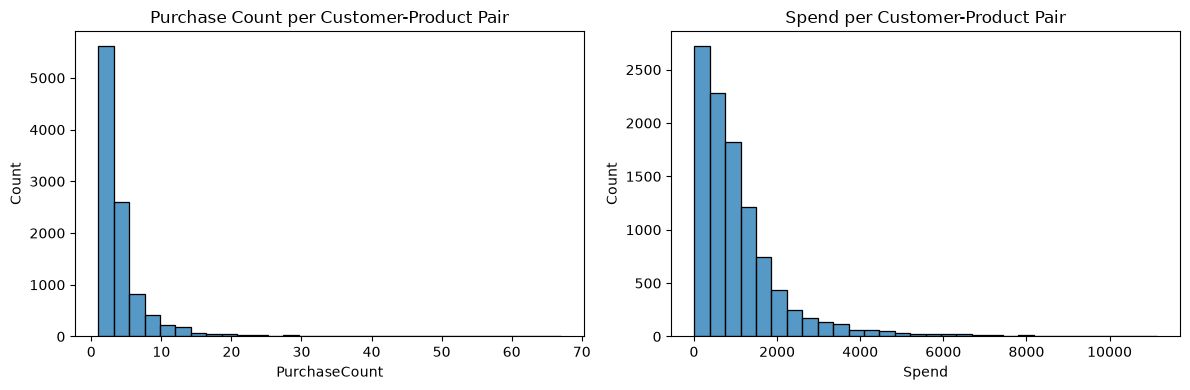

PurchaseCount   4.88
Spend           2.89
dtype: float64


In [20]:
fig, axes = plt.subplots(1, 2, figsize = (12, 4))
sns.histplot(df['PurchaseCount'], bins = 30, ax = axes[0])
axes[0].set_title('Purchase Count per Customer-Product Pair')
sns.histplot(df['Spend'], bins = 30, ax = axes[1])
axes[1].set_title('Spend per Customer-Product Pair')
plt.tight_layout()
plt.show()
print(df[['PurchaseCount', 'Spend']].skew())

## Exploratory Data Analysis

### Distribution of Purchase Count and Spend
Both variables are heavily right-skewed (skewness of about 4.9 for PurchaseCount and 2.9 for Spend). Most customer-product pairs involve only a small number of purchases and modest spend, while a few pairs have very high values, with purchase counts reaching 67 and spend in the thousands.

This matters for the recommender. If raw values were used as ratings, a small group of heavy buyers would dominate the similarity calculations. The implicit rating will therefore need to cap or transform these values (for example with a log transform) so that all customers contribute fairly.

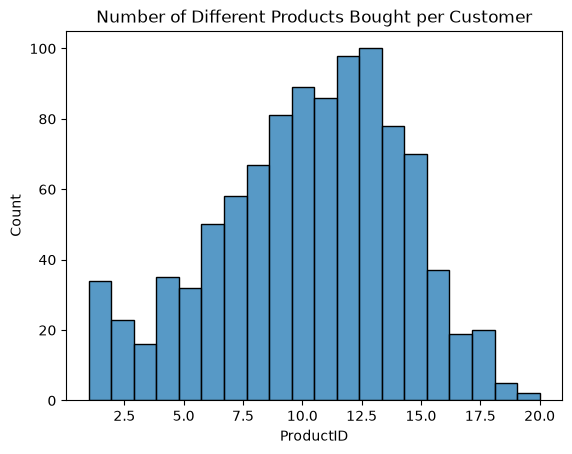

count   1000.00
mean      10.26
std        4.15
min        1.00
25%        8.00
50%       11.00
75%       13.00
max       20.00
Name: ProductID, dtype: float64


In [21]:
products_per_customer = df.groupby('CustomerID')['ProductID'].nunique()
sns.histplot(products_per_customer, bins = 20)
plt.title('Number of Different Products Bought per Customer')
plt.show()
print(products_per_customer.describe())

## Products Bought per Customer
The typical customer has bought only around 11 of the 200 available products, ranging from 1 to 20. Around 73 customers have bought three products or fewer, so there is very little history to base recommendations on for them.

This limited purchase history is a key challenge for collaborative filtering and links directly to the cold-start problem discussed later.

In [22]:
sparsity = 1 - len(df) / (df['CustomerID'].nunique() * df['ProductID'].nunique())
print(round(sparsity * 100, 2), '% of customer-product pairs have no purchase')

94.87 % of customer-product pairs have no purchase


Only about 5% of possible customer-product combinations contain a purchase

In [23]:
top_products = df.groupby('ProductID').agg(Buyers = ('CustomerID', 'nunique'),
                                           Purchases = ('PurchaseCount', 'sum')).sort_values('Buyers', ascending = False).head(10)
top_products

,Buyers,Purchases
ProductID,,
12,189,2326
64,183,5832
76,177,2383
137,166,1447
198,163,1405
73,160,1041
44,150,1052
114,148,873
6,136,664


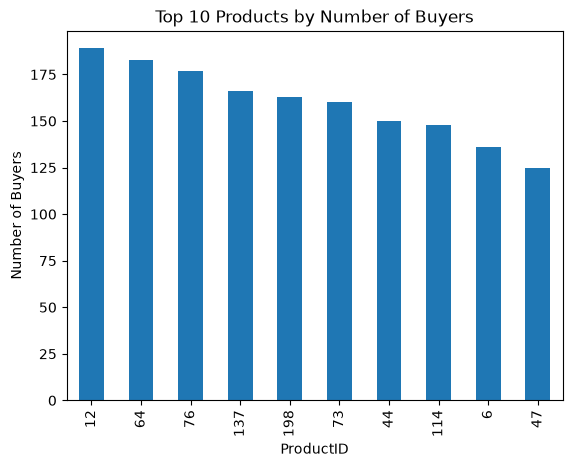

In [24]:
top_products['Buyers'].plot(kind = 'bar')
plt.title('Top 10 Products by Number of Buyers')
plt.ylabel('Number of Buyers')
plt.show()

### Most Popular Products
Product 12 has the most buyers (189 of 1,000 customers), followed closely by products 64 and 76. However, "popular" can be defined in two ways. Product 64 has far more total purchases (about 5,800) than product 12 (about 2,300), which means a smaller group of customers is buying it repeatedly.

Ranking by number of buyers measures breadth of appeal, while ranking by total purchases measures volume. For the popularity baseline I will rank by the number of buyers, since recommending something many different customers have chosen is more likely to suit a new customer than something a few customers buy in bulk.

In [25]:
category_summary = df.groupby('Category').agg(Purchases = ('PurchaseCount', 'sum'),
                                              TotalSpend = ('Spend', 'sum'),
                                              Pairs = ('ProductID', 'size'))
category_summary

,Purchases,TotalSpend,Pairs
Category,,,
Books,10377,2122416.77,1589
Electronics,4716,1214549.28,1354
Fitness,6123,1403313.00,1485
Gaming,6706,1996015.62,1607
Home,5304,1148351.73,1508
Kitchen,6999,1830066.69,1555
books,470,212787.70,127
electronics,855,231089.37,269
fitness,2772,423298.28,343


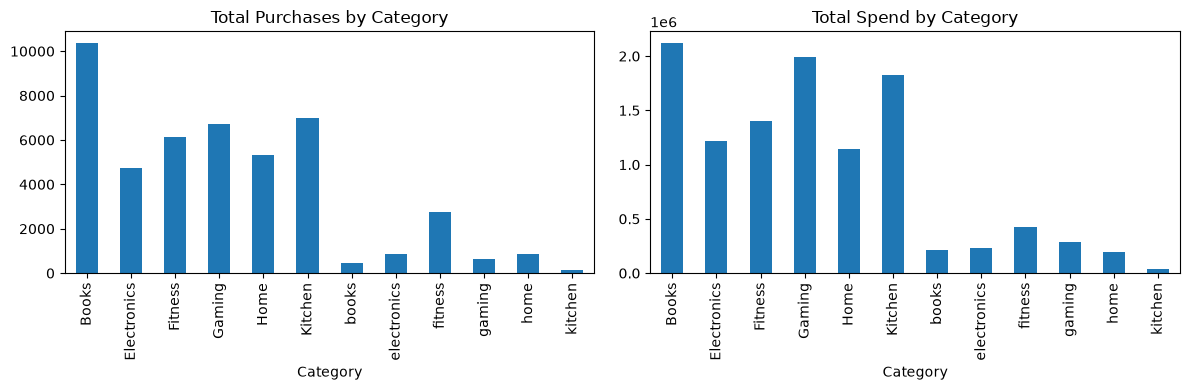

In [26]:
fig, axes = plt.subplots(1, 2, figsize = (12, 4))
category_summary['Purchases'].plot(kind = 'bar', ax = axes[0], title = 'Total Purchases by Category')
category_summary['TotalSpend'].plot(kind = 'bar', ax = axes[1], title = 'Total Spend by Category')
plt.tight_layout()
plt.show()

### Category Performance
Books is the strongest category for both total purchases (about 10,800) and total spend (about £2.3m), with Gaming close behind on spend. Electronics has the fewest purchases and Home the lowest spend.

Note that the Category column initially contained inconsistent capitalisation (for example "Books" and "books"), which was standardised during cleaning. Without this fix each category would have been split in two, understating its true performance.

In [27]:
loyalty_summary = df.groupby('LoyaltyLevel').agg(CustomerCount = ('CustomerID', 'nunique'),
                                                 AvgSpendPerPair = ('Spend', 'mean'))
loyalty_summary

,CustomerCount,AvgSpendPerPair
LoyaltyLevel,,
Bronze,493,1103.77
Gold,187,1039.35
Silver,320,1073.96


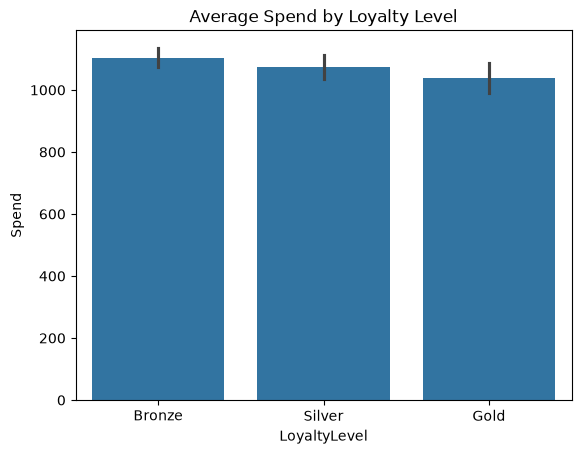

In [28]:
sns.barplot(data = df, x = 'LoyaltyLevel', y = 'Spend', order = ['Bronze', 'Silver', 'Gold'])
plt.title('Average Spend by Loyalty Level')
plt.show()

### Loyalty Level
Average spend per customer-product pair is very similar across loyalty tiers (roughly 1,040 to 1,100), with Bronze slightly higher than Gold. Bronze is also the largest group (493 customers, against 187 Gold).

This suggests loyalty level is not a strong signal of how much a customer spends per product. It may therefore add little value as a feature for recommendations. From a business perspective, it also raises the question of whether the loyalty programme is encouraging higher spending.

### Key Findings and Design Decisions
purchase count and spend are heavily skewed
about 95% of customer-product pairs are empty
popularity can be defined in two ways: by number of buyers or by total purchases
loyalty tiers are not a useful feature, high loyalty tier does not equal more spending

In [29]:
#log transform reduces the skew found in the EDA
df['LogPurchases'] = np.log1p(df['PurchaseCount'])
df['LogSpend'] = np.log1p(df['Spend'])
print(df[['LogPurchases', 'LogSpend']].skew())

LogPurchases    1.02
LogSpend       -0.63
dtype: float64


In [30]:
#scale each between 0 and 1
def scale(s):
    return (s - s.min()) / (s.max() - s.min())

#blend purchases and spend equally, then stretch to a 1-5 scale
df['ImplicitRating'] = 1 + 4 * (0.5 * scale(df['LogPurchases']) + 0.5 * scale(df['LogSpend']))
df['ImplicitRating'].describe()

count   10263.00
mean        2.62
std         0.60
min         1.00
25%         2.20
50%         2.63
75%         2.96
max         5.00
Name: ImplicitRating, dtype: float64

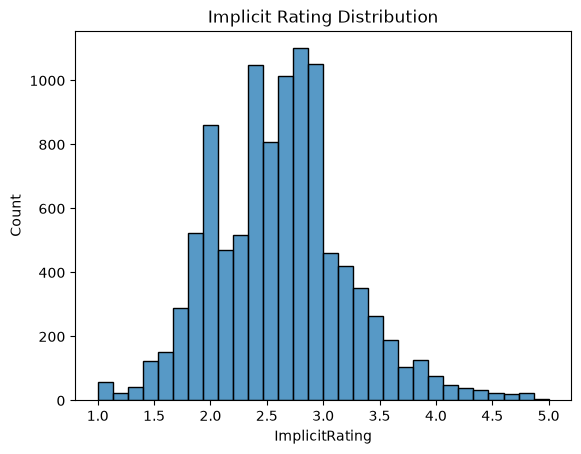

In [31]:
sns.histplot(df['ImplicitRating'], bins = 30)
plt.title('Implicit Rating Distribution')
plt.show()

In [32]:
np.random.seed(42)
test_index = []

#hold out about 20% of each customer's products (at least 1)
#customers with fewer than 3 products stay entirely in training
for customer_id, group in df.groupby('CustomerID'):
    if len(group) >= 3:
        n_test = max(1, int(round(len(group) * 0.2)))
        test_index += list(group.sample(n = n_test, random_state = 42).index)

test = df.loc[test_index]
train = df.drop(test_index)
print('Train rows:', len(train), '| Test rows:', len(test))
print('Customers in test:', test['CustomerID'].nunique())

Train rows: 8210 | Test rows: 2053
Customers in test: 943


In [33]:
#customer x product matrix, built from TRAINING data only
train_matrix = train.pivot_table(index = 'CustomerID', columns = 'ProductID',
                                 values = 'ImplicitRating', fill_value = 0)
train_matrix.shape

(1000, 200)

About 20% of each customer's purchased products were held out as a test set, and the rest were used for training.
Customers with fewer than three products (57 customers) were kept entirely in the training set, since holding out a purchase would leave almost nothing to learn from.
This means evaluation covers 943 of the 1,000 customers.


In [34]:
#rank products by number of different customers who bought them (training data only)
popularity = train.groupby('ProductID')['CustomerID'].nunique().sort_values(ascending = False)
popularity.head(10)

ProductID
76     162
198    148
73     146
12     141
137    136
44     127
64     126
114    124
47     118
186    114
Name: CustomerID, dtype: int64

## Popularity Baseline

As a benchmark, a simple non-personalised recommender was built. It ranks products by the number of different customers who bought them in the training data and recommends the top K products the customer has not already bought. Every customer with the same purchase history receives the same list, so this model has no personalisation, but it is a strong benchmark because popular products are bought often.

Any more advanced model needs to beat this baseline to justify its added complexity.

In [35]:
#what each customer bought in training, and what they actually bought in the test set
train_items = train.groupby('CustomerID')['ProductID'].apply(set).to_dict()
test_items = test.groupby('CustomerID')['ProductID'].apply(set).to_dict()

In [36]:
def recommend_popular(customer_id, k = 10):
    #skip anything the customer has already bought
    already_bought = train_items.get(customer_id, set())
    recs = [p for p in popularity.index if p not in already_bought]
    return recs[:k]

recommend_popular(1, 5)

[76, 198, 73, 12, 137]

In [37]:
def evaluate(recommend_function, k = 10):
    precisions, recalls, hits = [], [], []
    for customer_id, actual in test_items.items():
        recs = recommend_function(customer_id, k)
        correct = len(set(recs) & actual)
        precisions.append(correct / k)
        recalls.append(correct / len(actual))
        hits.append(1 if correct > 0 else 0)
    return {'Precision@K': np.mean(precisions),
            'Recall@K': np.mean(recalls),
            'HitRate@K': np.mean(hits)}

## Evaluation Method
Recommendations were scored against the held-out test purchases for 943 customers, using three metrics at K = 5 and K = 10:
- Precision@K: the share of the K recommended products that the customer actually bought.
- Recall@K: the share of the customer's held-out purchases that appeared in the K recommendations.
- Hit Rate@K: the share of customers for whom at least one recommended product was a real purchase.

In [38]:
results = []
for k in [5, 10]:
    scores = evaluate(recommend_popular, k)
    results.append({'Model': 'Popularity', 'K': k, **scores})

results_df = pd.DataFrame(results)
results_df

,Model,K,Precision@K,Recall@K,HitRate@K
0,Popularity,5,0.03,0.06,0.13
1,Popularity,10,0.03,0.15,0.25


### Baseline Results
The popularity baseline achieved a hit rate of about 25% at K = 10, meaning roughly one in four customers received at least one product they went on to buy. Precision is low (about 0.03), but this is expected because each customer has only a couple of held-out purchases to find.

In [39]:
from sklearn.metrics.pairwise import cosine_similarity

#customer x product matrix, built from TRAINING data only
train_matrix = train.pivot_table(index = 'CustomerID', columns = 'ProductID',
                                 values = 'ImplicitRating', fill_value = 0)

#cosine similarity between every pair of products (based on who bought them)
sim_array = cosine_similarity(train_matrix.T)
#a product is always identical to itself, so set the diagonal to 0
np.fill_diagonal(sim_array, 0)
item_sim = pd.DataFrame(sim_array, index = train_matrix.columns, columns = train_matrix.columns)
item_sim.shape

(200, 200)

In [40]:
def recommend_item_cf(customer_id, k = 10):
    #fall back to popularity for any customer with no training history
    if customer_id not in train_matrix.index:
        return recommend_popular(customer_id, k)

    #score each product by how similar it is to the products the customer rated
    ratings = train_matrix.loc[customer_id]
    scores = item_sim.dot(ratings)

    #remove products the customer has already bought
    scores = scores.drop(labels = list(train_items.get(customer_id, set())))
    return scores.sort_values(ascending = False).head(k).index.tolist()

recommend_item_cf(1, 5)

[49, 114, 47, 134, 142]

## Item-Based Collaborative Filtering
Item-based collaborative filtering recommends products that are similar to those a customer has already bought.

In [41]:
for k in [5, 10]:
    results.append({'Model': 'Item-based CF', 'K': k, **evaluate(recommend_item_cf, k)})

results_df = pd.DataFrame(results)
results_df.round(3)

,Model,K,Precision@K,Recall@K,HitRate@K
0,Popularity,5,0.03,0.06,0.13
1,Popularity,10,0.03,0.15,0.25
2,Item-based CF,5,0.16,0.38,0.62
3,Item-based CF,10,0.12,0.56,0.81


### Results
Item-based collaborative filtering performed far better than the popularity baseline. At K = 10 it achieved a hit rate of about 81%, compared with about 25% for popularity, and recall rose from about 0.15 to 0.56.

In [42]:
from sklearn.preprocessing import StandardScaler

#describe each product by category, brand and price
product_features = products.set_index('ProductID')[['Category', 'Brand', 'Price']]
category_brand = pd.get_dummies(product_features[['Category', 'Brand']]).astype(float)
price_scaled = pd.DataFrame(StandardScaler().fit_transform(product_features[['Price']]),
                            index = product_features.index, columns = ['Price'])
content_features = pd.concat([category_brand, price_scaled], axis = 1)

#cosine similarity between every pair of products
content_array = cosine_similarity(content_features)
np.fill_diagonal(content_array, 0)
content_sim = pd.DataFrame(content_array, index = content_features.index, columns = content_features.index)

#line up with the columns of the training matrix
content_sim = content_sim.reindex(index = train_matrix.columns, columns = train_matrix.columns)
content_sim.shape

(200, 200)

In [43]:
def recommend_content(customer_id, k = 10):
    if customer_id not in train_matrix.index:
        return recommend_popular(customer_id, k)
    scores = content_sim.dot(train_matrix.loc[customer_id])
    scores = scores.drop(labels = list(train_items.get(customer_id, set())))
    return scores.sort_values(ascending = False).head(k).index.tolist()

recommend_content(1, 5)

[196, 191, 136, 128, 103]

## Content-Based Recommender

Content-based filtering describes each product by its attributes (category, brand and scaled price) and recommends products similar to those a customer has already bought. Unlike collaborative filtering, it does not rely on other customers' behaviour, so it can recommend brand new products with no purchase history.

### Results
The content-based model performed much worse than collaborative filtering and also worse than the popularity baseline (hit rate about 11% at K = 10, against 81% for item-based CF and 25% for popularity). It performs close to what random recommendations achieve (about 10%). This suggests that category, brand and price are not strong drivers of what customers buy in this dataset. This is consistent with the EDA, where purchase patterns showed little relationship with customer age group or region. Customers seem to buy products that are bought together, rather than products that are alike in their attributes.

In [44]:
results = []
for k in [5, 10]:
    results.append({'Model': 'Popularity', 'K': k, **evaluate(recommend_popular, k)})
    results.append({'Model': 'Item-based CF', 'K': k, **evaluate(recommend_item_cf, k)})
    results.append({'Model': 'Content-based', 'K': k, **evaluate(recommend_content, k)})

results_df = pd.DataFrame(results).round(3)
results_df.sort_values(['K', 'HitRate@K'], ascending = [True, False])

,Model,K,Precision@K,Recall@K,HitRate@K
1,Item-based CF,5,0.16,0.38,0.62
0,Popularity,5,0.03,0.06,0.13
2,Content-based,5,0.01,0.03,0.06
4,Item-based CF,10,0.12,0.56,0.81
3,Popularity,10,0.03,0.15,0.25
5,Content-based,10,0.01,0.05,0.11


In [45]:
new_product = 190
print(products.set_index('ProductID').loc[new_product, ['Category', 'Brand', 'Price']])

#find the most similar products using attributes alone
similar = content_sim.loc[new_product].sort_values(ascending = False).head(5)
products.set_index('ProductID').loc[similar.index, ['Category', 'Brand', 'Price']].assign(Similarity = similar)

Category    Electronics
Brand           FitLife
Price            194.07
Name: 190, dtype: object


,Category,Brand,Price,Similarity
ProductID,,,,
140,Electronics,FitLife,157.37,0.99
39,Electronics,FitLife,123.21,0.96
98,Electronics,FitLife,297.32,0.88
139,Electronics,FitLife,311.24,0.84
107,Electronics,FitLife,330.03,0.79
